<a href="https://colab.research.google.com/github/Ohsoo46/first-repository/blob/main/cs_project01_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [110]:
import pandas as pd
user_data = pd.read_csv('/user_data.csv')

In [111]:
user_data.head()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate
0,14581,1,217,16,139.0,139.0,16,0.0,1,0,0.0
1,18181,1,133,24,367.0,367.0,40,0.0,1,0,0.0
2,12538,1,191,29,364.0,364.0,21,0.0,1,0,0.0
3,17011,1,186,30,271.0,271.0,15,0.0,1,0,0.0
4,13103,1,82,39,244.0,244.0,8,0.0,1,0,0.0


In [112]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=user_data)

https://docs.google.com/spreadsheets/d/1KANokVRv25UtrPH2lqaL33UXaqGEMTjcl609sWLMUBQ/edit#gid=0


In [113]:
from scipy import stats
import numpy as np


In [114]:
# Z-score 계산
z_scores = stats.zscore(user_data.iloc[:, 1:], axis=0)

# Z-score 절대값 계산
z_scores = np.abs(z_scores)

# Z-score 출력
z_scores

array([[ 0.43970865,  0.1928588 ,  0.74986819, ...,  0.43970865,
         0.39467476,  0.60293741],
       [ 0.43970865,  0.21085145,  0.67062995, ...,  0.43970865,
         0.39467476,  0.60293741],
       [ 0.43970865,  0.19842796,  0.62110605, ...,  0.43970865,
         0.39467476,  0.60293741],
       ...,
       [18.05880088,  4.60432497,  0.8984399 , ..., 18.05880088,
        22.5120992 ,  0.89901926],
       [23.34408932,  4.79774598,  0.90834469, ..., 23.34408932,
         5.20475887,  0.31698472],
       [26.09684372, 16.21601152,  0.8984399 , ..., 26.09684372,
        22.00305978,  0.42243143]])

In [115]:
# 임계값(threshold) 설정
threshold = 3

# z-score 기준으로 이상치를 찾아서 outlier 컬럼에 이상치 여부 기입 (0: 정상, 1:이상치)
user_data['outlier'] = (z_scores > threshold).any(axis=1).astype(int)
user_data.head()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate,outlier
0,14581,1,217,16,139.0,139.0,16,0.0,1,0,0.0,0
1,18181,1,133,24,367.0,367.0,40,0.0,1,0,0.0,0
2,12538,1,191,29,364.0,364.0,21,0.0,1,0,0.0,0
3,17011,1,186,30,271.0,271.0,15,0.0,1,0,0.0,0
4,13103,1,82,39,244.0,244.0,8,0.0,1,0,0.0,0


/tmp/ipython-input-123714402.py:6: FutureWarning:

pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.



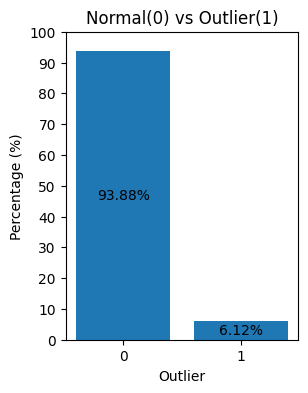

In [116]:
# 시각화에 필요한 라이브러리 불러오기
import matplotlib.pyplot as plt

# user_data['outlier']을 활용하여 이상치 여부에 따른 확률 계산
# value_counts()는 열의 고윳값의 개수를 반환하지만 normalize=True를 사용하면 열에 있는 값의 개수 비율(상대적 빈도)을 반환함
outlier_percentage = pd.value_counts(user_data['outlier'], normalize=True) * 100

# 시각화 자료 크기 조정
plt.figure(figsize=(3, 4))

# outlier_percentage라는 데이터로 bar chart 시각화
# x축 값을 0과 1로 지정
bars = plt.bar(['0', '1'], outlier_percentage)

# 퍼센트(%) 표시
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval/2, f'{yval:.2f}%', fontsize=10, va='center', ha='center')

plt.title('Normal(0) vs Outlier(1)') # 표 제목
plt.yticks(ticks=np.arange(0, 101, 10)) # y축 표기 (0~100까지 10단위로 증가)
plt.ylabel('Percentage (%)') # y축 범례
plt.xlabel('Outlier') # x축 범례
plt.show() # 출력

In [117]:
# 정상 데이터만 필터링
user_data = user_data[user_data['outlier'] == 0]

# outlier 컬럼 삭제
user_data = user_data.drop(columns=['outlier'])

# DataFrame의 인덱스를 리셋하고, 이전 인덱스를 컬럼으로 추가하지 않음
user_data.reset_index(inplace=True, drop=True)
user_data.head()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate
0,14581,1,217,16,139.0,139.0,16,0.0,1,0,0.0
1,18181,1,133,24,367.0,367.0,40,0.0,1,0,0.0
2,12538,1,191,29,364.0,364.0,21,0.0,1,0,0.0
3,17011,1,186,30,271.0,271.0,15,0.0,1,0,0.0
4,13103,1,82,39,244.0,244.0,8,0.0,1,0,0.0


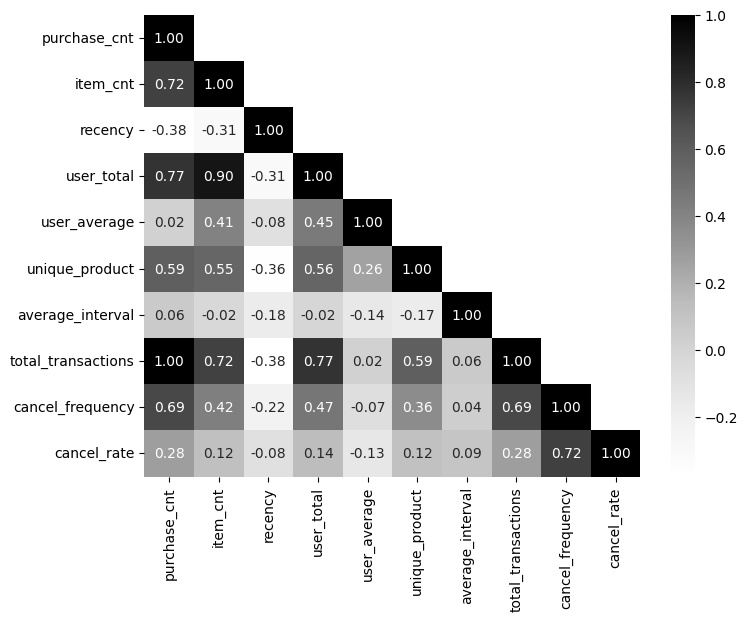

In [118]:
# 시각화 라이브러리 불러오기 (변수간 상관관계 분)
import seaborn as sns

# 'CustomerID' 열을 제외(drop)하고 상관 관계 행렬 계산(corr())
corr = user_data.drop(columns=['CustomerID']).corr()

# 행렬이 대각선을 기준으로 대칭이기 때문에 하단만 표시하기 위한 마스크 생성
mask = np.zeros_like(corr) # np.zeros_like()는 0으로 가득찬 array 생성, 크기는 corr와 동일
mask[np.triu_indices_from(mask, k=1)] = True # array의 대각선 영역과 그 윗 부분에 True가 들어가도록 설정

# 히트맵 그리기
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, cmap='Greys', annot=True, fmt='.2f')
plt.show()

In [119]:
# Standard Scaler 불러오기 (12-4. 피터 스케일)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [120]:
# 원본 데이터에 영향을 주지 않기 위해 복사
data = user_data.copy()

# CustomerID를 제외한 데이터에 스케일링 적용
columns_list = data.iloc[:, 1:].columns # iloc: 데이터 특정 값 추출, columns: 데이터프레임의 열 이름 조회
data[columns_list] = scaler.fit_transform(data[columns_list])

In [121]:
# 스케일링 된 데이터 출력
data.head()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate
0,14581,-0.713465,-0.479917,-0.767416,-0.617747,-0.722240,-0.685840,-0.584525,-0.713465,-0.539844,-0.604378
1,18181,-0.713465,-0.560685,-0.687493,-0.484667,0.362743,-0.257383,-0.584525,-0.713465,-0.539844,-0.604378
2,12538,-0.713465,-0.504916,-0.637541,-0.486418,0.348467,-0.596578,-0.584525,-0.713465,-0.539844,-0.604378
3,17011,-0.713465,-0.509724,-0.627551,-0.540701,-0.094092,-0.703692,-0.584525,-0.713465,-0.539844,-0.604378
4,13103,-0.713465,-0.609722,-0.537637,-0.556460,-0.222577,-0.828659,-0.584525,-0.713465,-0.539844,-0.604378


In [122]:
print(data.shape)
print(data.columns.tolist())

(4095, 11)
['CustomerID', 'purchase_cnt', 'item_cnt', 'recency', 'user_total', 'user_average', 'unique_product', 'average_interval', 'total_transactions', 'cancel_frequency', 'cancel_rate']


In [123]:
# 12-5. 차원축소
#PCA 불러오기

from sklearn.decomposition import PCA

# CustomerID를 인덱스로 지정
data.set_index('CustomerID', inplace = True)
# PCA 적용
pca = PCA().fit(data)

In [124]:
df = data.reset_index()                   # 'CustomerID'라는 열 생성
X = df.drop(columns=['CustomerID'])       # ID는 제거하고 수치만
pca = PCA().fit(X)


In [125]:
print("index name:", data.index.name)     # 'CustomerID'일 것


index name: CustomerID


In [126]:
print(data.shape)
print(data.columns.tolist())

(4095, 10)
['purchase_cnt', 'item_cnt', 'recency', 'user_total', 'user_average', 'unique_product', 'average_interval', 'total_transactions', 'cancel_frequency', 'cancel_rate']


In [127]:
# Explained Variance의 누적합 계산
explained_variance_ratio = pca.explained_variance_ratio_ # explained_variance_ratio_: Explained Variance 비율을 계산해 주는 함수
cumulative_explained_variance = np.cumsum(explained_variance_ratio) # cumsum: 각 원소의 누적합을 계산하는 함수

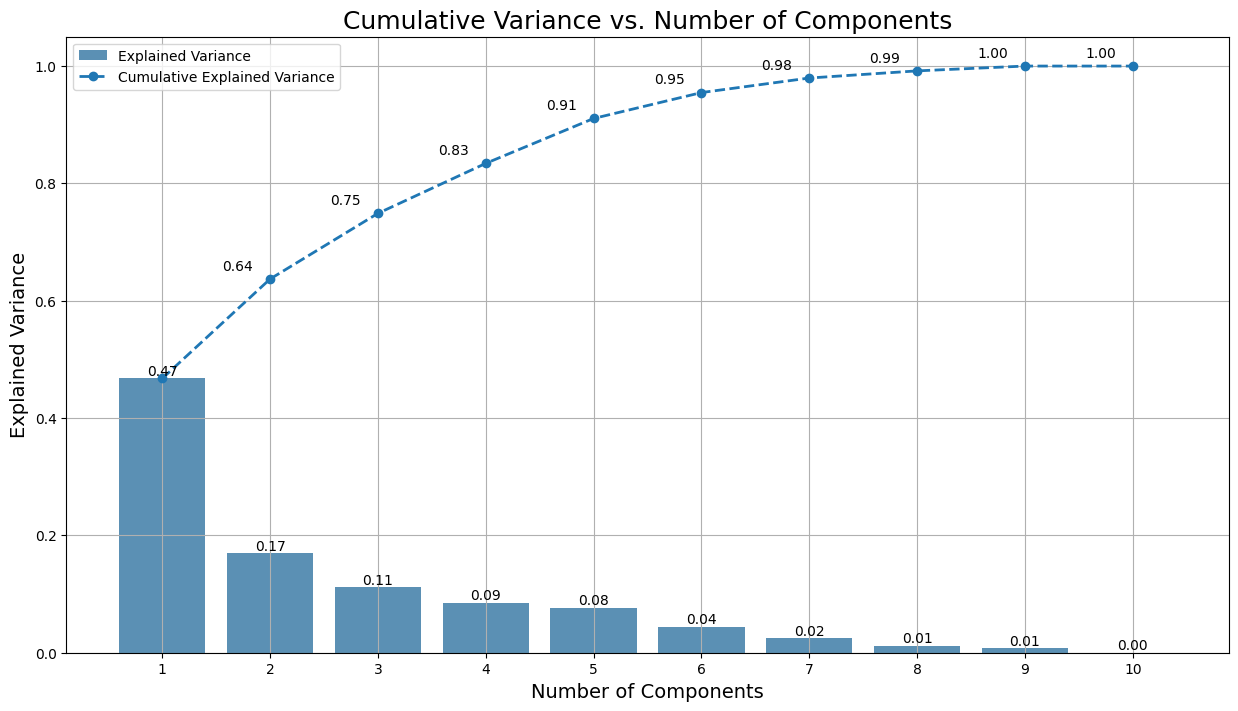

In [128]:
plt.figure(figsize=(15, 8))

# 각 성분의 설명된 분포에 대한 막대 그래프
barplot = sns.barplot(x=list(range(1, len(cumulative_explained_variance) + 1)), y=explained_variance_ratio, alpha=0.8)

# 누적 분포에 대한 선 그래프
lineplot, = plt.plot(range(0, len(cumulative_explained_variance)), cumulative_explained_variance, marker='o', linestyle='--', linewidth=2)

# 레이블과 제목 설정
plt.xlabel('Number of Components', fontsize=14)
plt.ylabel('Explained Variance', fontsize=14)
plt.title('Cumulative Variance vs. Number of Components', fontsize=18)

# 눈금 및 범례 사용자 정의
plt.xticks(range(0, len(cumulative_explained_variance)))
plt.legend(handles=[barplot.patches[0], lineplot],
           labels=['Explained Variance', 'Cumulative Explained Variance'])

# 두 그래프의 분산 값 표시
x_offset = -0.3
y_offset = 0.01
for i, (ev_ratio, cum_ev_ratio) in enumerate(zip(explained_variance_ratio, cumulative_explained_variance)):
    plt.text(i, ev_ratio, f"{ev_ratio:.2f}", ha="center", va="bottom", fontsize=10)
    if i > 0:
        plt.text(i + x_offset, cum_ev_ratio + y_offset, f"{cum_ev_ratio:.2f}", ha="center", va="bottom", fontsize=10)

plt.grid(axis='both')
plt.show()

In [129]:
# 6개의 주성분을 유지하는 PCA 선언
pca = PCA(n_components = 6)

# 기존 data를  pca에 fit_transform
data_pca = pca.fit_transform(data)

#압축된 데이터 셋 생성
data_pca = pd.DataFrame(data_pca, columns=['PC' + str(i + 1)for i in range(pca.n_components_)])

#인덱스로 빼 두었던 CustomerID 다시 추가
data_pca.index = data.index

In [130]:
# 최종결과 출력
data_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6
CustomerID,,,,,,
14581,-1.485987,0.052051,0.321649,-0.865932,-0.580435,-0.824200
18181,-1.218306,0.747844,0.153718,-0.322195,-0.915943,-0.411764
12538,-1.320053,0.688683,0.160115,-0.207588,-0.771214,-0.677367
17011,-1.431143,0.408464,0.199728,-0.446159,-0.630457,-0.768697
13103,-1.551377,0.285057,0.172096,-0.482118,-0.520143,-0.821870


12-6. K-Means 클러스터링

In [131]:
# ?  k=3은 “의미 있게 구분되면서도 과적합을 피하는 최소 세분화 , silhouette , 엘보 등  확인하여 최적의 k 군집수를 찾아나감
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans
import numpy as np

X = data_pca.drop(columns=['cluster'], errors='ignore').values if hasattr(data_pca, 'columns') else data_pca

ks = range(2, 9)
metrics = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    labels = km.labels_
    inertia = km.inertia_
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    metrics.append((k, inertia, sil, db))

for k, inertia, sil, db in metrics:
    print(f"k={k}  inertia={inertia:.0f}  silhouette={sil:.3f}  DB={db:.3f}")


k=2  inertia=26742  silhouette=0.430  DB=1.152
k=3  inertia=22221  silhouette=0.301  DB=1.334
k=4  inertia=19223  silhouette=0.305  DB=1.272
k=5  inertia=16755  silhouette=0.323  DB=1.177
k=6  inertia=14549  silhouette=0.285  DB=1.147
k=7  inertia=12951  silhouette=0.294  DB=1.118
k=8  inertia=11801  silhouette=0.300  DB=1.126


In [132]:
from sklearn.cluster import KMeans
from collections import Counter

# k= 3개의 클러스터로  K-Means 클러스터링 적용
kmeans = KMeans(n_clusters = 3, init = 'k-means++', n_init = 10, max_iter = 100, random_state = 0)
kmeans.fit(data_pca)

# 각 클러스터의 빈도수 구하기
cluster_frequencies = Counter(kmeans.labels_)

# 빈도수에 기반하여 이전 레이블에서 새 레이블로의 매핑 생성
label_mapping = {label: new_label for new_label, (label, _) in
                    enumerate(cluster_frequencies.most_common())}

# 매핑을 적용하여 새 레이블 얻기
new_labels = np.array([label_mapping[label] for label in kmeans.labels_])

#원래 데이터셋에 새 클러스터 레이블 추가
user_data['cluster'] = new_labels

#PCA버전의 데이터셋에 새 클러스터 레이블 추가
data_pca['cluster'] = new_labels



In [133]:
# K-Means 분류된 결과 보기
user_data.head()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate,cluster
0,14581,1,217,16,139.0,139.0,16,0.0,1,0,0.0,0
1,18181,1,133,24,367.0,367.0,40,0.0,1,0,0.0,0
2,12538,1,191,29,364.0,364.0,21,0.0,1,0,0.0,0
3,17011,1,186,30,271.0,271.0,15,0.0,1,0,0.0,0
4,13103,1,82,39,244.0,244.0,8,0.0,1,0,0.0,0


In [134]:
# 각 군집별로 몇 명의 고객이 있는지 확인
user_data.value_counts('cluster')

,count
cluster,
0,2664
1,1021
2,410


12-7. 시각화 및 결과 분석

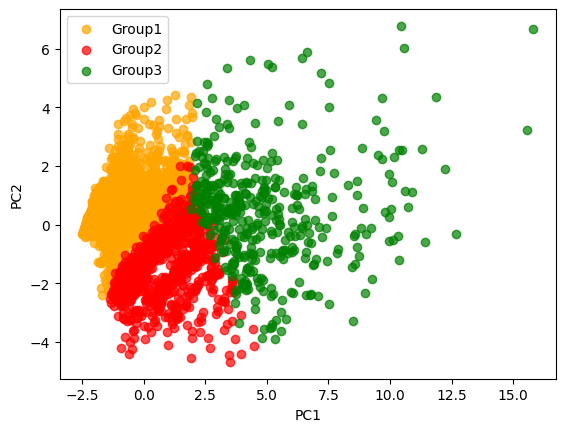

In [135]:
# 각 클러스터 별 데이터 분리
cluster_0 = data_pca[data_pca['cluster'] == 0]
cluster_1 = data_pca[data_pca['cluster'] == 1]
cluster_2 = data_pca[data_pca['cluster'] == 2]


# 클러스터 별 시각화
plt.scatter(cluster_0['PC1'], cluster_0['PC2'], color = 'orange', alpha = 0.7, label = 'Group1')
plt.scatter(cluster_1['PC1'], cluster_1['PC2'], color = 'red', alpha = 0.7, label = 'Group2')
plt.scatter(cluster_2['PC1'], cluster_2['PC2'], color = 'green', alpha = 0.7, label = 'Group3')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

3D 시각화

In [109]:
# 시각화 라이브러리
!pip install plotly==5.18.0

In [108]:
# 색상 지정
colors = ['red', 'blue', 'green']

# 각 클러스터별 데이터 분릴
cluster_0 = data_pca[data_pca['cluster'] == 0]
cluster_1 = data_pca[data_pca['cluster'] == 1]
cluster_2 = data_pca[data_pca['cluster'] == 2]

# 3D Scatter Plot 생성
import plotly.graph_objects as go
fig = go.Figure()

# 각 클러스터별 데이터 표기
fig.add_trace(go.Scatter3d(x=cluster_0['PC1'], y=cluster_0['PC2'], z=cluster_0['PC3'],
                           mode='markers', marker=dict(color=colors[0], size=5, opacity=0.4), name='Group 1'))
fig.add_trace(go.Scatter3d(x=cluster_1['PC1'], y=cluster_1['PC2'], z=cluster_1['PC3'],
                           mode='markers', marker=dict(color=colors[1], size=5, opacity=0.4), name='Group 2'))
fig.add_trace(go.Scatter3d(x=cluster_2['PC1'], y=cluster_2['PC2'], z=cluster_2['PC3'],
                           mode='markers', marker=dict(color=colors[2], size=5, opacity=0.4), name='Group 3'))

# 범례 및 제목 영역 설정
fig.update_layout(
    title=dict(text='3D Visualization of Customer Clusters in PCA Space', x=0.5),
    scene=dict(
        xaxis=dict(backgroundcolor="grey", gridcolor='white', title='PC1'),
        yaxis=dict(backgroundcolor="grey", gridcolor='white', title='PC2'),
        zaxis=dict(backgroundcolor="grey", gridcolor='white', title='PC3'),
    ),
    width=900,
    height=800
)

fig.show()

In [137]:
group1 = user_data[user_data['cluster'] == 0]
group2 = user_data[user_data['cluster'] == 1]
group3 = user_data[user_data['cluster'] == 2]

In [138]:
group1.describe()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate,cluster
count,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.0,2664.0,2664.0
mean,15349.274399,2.197447,394.288664,110.292793,645.113739,297.453829,39.778529,2.312965,2.197447,0.0,0.0,0.0
std,1715.908336,1.661354,428.796440,105.346382,649.765162,211.478177,41.184432,4.556432,1.661354,0.0,0.0,0.0
min,12348.000000,1.000000,1.000000,0.000000,4.000000,4.000000,1.000000,0.000000,1.000000,0.0,0.0,0.0
25%,13843.250000,1.000000,117.000000,25.000000,215.750000,154.000000,12.000000,0.000000,1.000000,0.0,0.0,0.0
50%,15393.500000,2.000000,242.500000,66.000000,410.000000,239.500000,26.000000,0.075000,2.000000,0.0,0.0,0.0
75%,16826.500000,3.000000,496.250000,180.500000,827.250000,372.000000,52.000000,2.690000,3.000000,0.0,0.0,0.0
max,18287.000000,11.000000,3412.000000,373.000000,4392.000000,1488.000000,312.000000,35.890000,11.000000,0.0,0.0,0.0


In [139]:
group2.describe()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate,cluster
count,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.000000,1021.0
mean,15229.359452,5.093046,667.715965,75.993144,1141.312439,226.442703,54.807052,3.726641,5.093046,1.446621,0.319381,1.0
std,1705.129611,2.554151,518.237736,87.849397,815.804848,150.386006,41.072473,4.778870,2.554151,0.850802,0.134939,0.0
min,12346.000000,2.000000,-303.000000,0.000000,-96.000000,-32.000000,1.000000,0.000000,2.000000,0.000000,0.000000,1.0
25%,13762.000000,3.000000,258.000000,15.000000,487.000000,130.000000,23.000000,1.070000,3.000000,1.000000,0.200000,1.0
50%,15208.000000,5.000000,542.000000,39.000000,983.000000,193.000000,46.000000,2.330000,5.000000,1.000000,0.333300,1.0
75%,16689.000000,7.000000,992.000000,100.000000,1625.000000,280.000000,77.000000,4.150000,7.000000,2.000000,0.500000,1.0
max,18282.000000,14.000000,2777.000000,372.000000,4912.000000,1301.000000,297.000000,36.000000,14.000000,6.000000,0.600000,1.0


In [140]:
group3.describe()

,CustomerID,purchase_cnt,item_cnt,recency,user_total,user_average,unique_product,average_interval,total_transactions,cancel_frequency,cancel_rate,cluster
count,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.000000,410.0
mean,15205.892683,13.629268,2927.792683,21.146341,4925.141463,407.558537,148.563415,1.744366,13.629268,2.126829,0.154318,2.0
std,1750.322608,5.775686,1838.123930,31.063435,3009.125373,265.042152,76.701320,1.680345,5.775686,1.742188,0.119992,0.0
min,12347.000000,3.000000,298.000000,0.000000,587.000000,39.000000,4.000000,0.010000,3.000000,0.000000,0.000000,2.0
25%,13759.250000,10.000000,1757.750000,4.000000,3016.750000,232.500000,94.000000,0.872500,10.000000,1.000000,0.062500,2.0
50%,15147.000000,13.000000,2442.500000,11.000000,4022.500000,327.000000,139.500000,1.300000,13.000000,2.000000,0.140400,2.0
75%,16727.250000,16.750000,3569.250000,25.750000,5764.500000,483.250000,207.250000,1.995000,16.750000,3.000000,0.250000,2.0
max,18283.000000,31.000000,14652.000000,267.000000,25186.000000,1482.000000,317.000000,15.810000,31.000000,6.000000,0.500000,2.0
